In [1]:
import os
import utils
import torch
import pickle
import numpy as np
import matplotlib.pyplot as plt

from torch import nn
from torch.utils.data import DataLoader, TensorDataset, RandomSampler

# PARAMETRI

In [2]:
ITERATIONS = 2000
BATCH_SIZE = 16
G_LEARNING_RATE = 0.0004
D_LEARNING_RATE = 0.0008
DISPLAY_INTERVAL = 100   # ogni quante iterazioni mostrare immagini generate e reali
DEVICE = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device('cpu')

print(f"DEVICE: {DEVICE}")

DEVICE: cuda


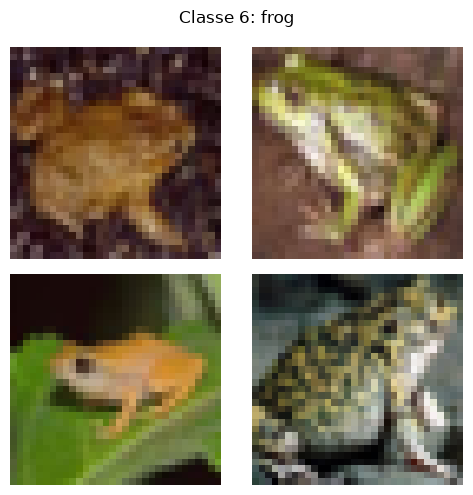

TRAIN SET shape: (2048, 3, 32, 32)
MIN: -1.0  MAX: 1.0


In [3]:
from datasets.datasets import load_CIFAR10
cifar_train, _, _, _ = load_CIFAR10(batch_size=BATCH_SIZE, verbose=False)

CLASS = 6          # 'frog'
TRAIN_SIZE = 2048

idx = np.where(np.array(cifar_train.targets) == CLASS)[0][:TRAIN_SIZE]
images = cifar_train.data[idx]   # array numpy (N, 32, 32, 3), valori interi in [0, 255]

plt.figure(figsize=(5, 5))
for i, j in enumerate(np.random.randint(0, len(images), 4)):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[j])
    plt.axis('off')
plt.suptitle(f"Classe {CLASS}: {cifar_train.classes[CLASS]}")
plt.tight_layout()
plt.show()

x_train = torch.tensor(images).permute(0, 3, 1, 2).float() / 255 * 2 - 1   # (N, 3, 32, 32) in [-1, 1], come l'uscita tanh del generatore
train_dataset = TensorDataset(x_train)
# Come nell'originale, ogni iterazione usa un batch estratto a caso (con ripetizione): ITERATIONS batch in tutto
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          sampler=RandomSampler(train_dataset, replacement=True, num_samples=ITERATIONS * BATCH_SIZE))

print(f"TRAIN SET shape: {tuple(x_train.shape)}")
print(f"MIN: {x_train.min():.1f}  MAX: {x_train.max():.1f}")

# MODELLO

In [4]:
#Parametri del modello
LATENT_SIZE = 32
CHANNELS = 3

In [5]:
# DISCRIMINATORE: da un'immagine al logit della probabilità che sia reale
discriminator = nn.Sequential(
    nn.Conv2d(CHANNELS, 256, 3), nn.LeakyReLU(0.3),            # (B, 3, 32, 32) -> (B, 256, 30, 30)
    nn.Conv2d(256, 256, 4, stride=2), nn.LeakyReLU(0.3),       # -> (B, 256, 14, 14)
    nn.Conv2d(256, 256, 4, stride=2), nn.LeakyReLU(0.3),       # -> (B, 256, 6, 6)
    nn.Conv2d(256, 256, 4, stride=2), nn.LeakyReLU(0.3),       # -> (B, 256, 2, 2)
    nn.Flatten(),                                                    # -> (B, 1024)
    nn.Dropout(0.4),
    nn.Linear(256 * 2 * 2, 1),                                       # -> (B, 1), logit: la sigmoide è dentro la loss
).to(DEVICE)

discriminator

Sequential(
  (0): Conv2d(3, 256, kernel_size=(3, 3), stride=(1, 1))
  (1): LeakyReLU(negative_slope=0.3)
  (2): Conv2d(256, 256, kernel_size=(4, 4), stride=(2, 2))
  (3): LeakyReLU(negative_slope=0.3)
  (4): Conv2d(256, 256, kernel_size=(4, 4), stride=(2, 2))
  (5): LeakyReLU(negative_slope=0.3)
  (6): Conv2d(256, 256, kernel_size=(4, 4), stride=(2, 2))
  (7): LeakyReLU(negative_slope=0.3)
  (8): Flatten(start_dim=1, end_dim=-1)
  (9): Dropout(p=0.4, inplace=False)
  (10): Linear(in_features=1024, out_features=1, bias=True)
)

In [6]:
# GENERATORE: da un vettore di rumore z a un'immagine 32x32 a colori
generator = nn.Sequential(
    nn.Linear(LATENT_SIZE, 128 * 16 * 16), nn.LeakyReLU(0.3),
    nn.Unflatten(1, (128, 16, 16)),                                          # (B, 32768) -> (B, 128, 16, 16)
    nn.Conv2d(128, 256, 5, padding='same', bias=False), nn.BatchNorm2d(256), # -> (B, 256, 16, 16)
    nn.LeakyReLU(0.3),
    nn.ConvTranspose2d(256, 256, 4, stride=2, padding=1, bias=False), nn.BatchNorm2d(256),# -> (B, 256, 32, 32)
    nn.LeakyReLU(0.3),
    nn.Conv2d(256, 256, 5, padding='same', bias=False), nn.BatchNorm2d(256),
    nn.LeakyReLU(0.3),
    nn.Conv2d(256, 256, 5, padding='same', bias=False),nn.BatchNorm2d(256),
    nn.LeakyReLU(0.3),
    nn.Conv2d(256, CHANNELS, 7, padding='same'), nn.Tanh(),                  # -> (B, 3, 32, 32), valori in [-1, 1]
).to(DEVICE)

generator

Sequential(
  (0): Linear(in_features=32, out_features=32768, bias=True)
  (1): LeakyReLU(negative_slope=0.3)
  (2): Unflatten(dim=1, unflattened_size=(128, 16, 16))
  (3): Conv2d(128, 256, kernel_size=(5, 5), stride=(1, 1), padding=same, bias=False)
  (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (5): LeakyReLU(negative_slope=0.3)
  (6): ConvTranspose2d(256, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
  (7): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (8): LeakyReLU(negative_slope=0.3)
  (9): Conv2d(256, 256, kernel_size=(5, 5), stride=(1, 1), padding=same, bias=False)
  (10): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (11): LeakyReLU(negative_slope=0.3)
  (12): Conv2d(256, 256, kernel_size=(5, 5), stride=(1, 1), padding=same, bias=False)
  (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True

In [7]:
g_optimizer = torch.optim.RMSprop(generator.parameters(), lr=G_LEARNING_RATE, alpha=0.9, eps=3e-4)
d_optimizer = torch.optim.RMSprop(discriminator.parameters(), lr=D_LEARNING_RATE, alpha=0.9, eps=3e-4)

criterion = nn.BCEWithLogitsLoss()

print(f"Parametri del generatore:     {sum(p.numel() for p in generator.parameters()):,}")
print(f"Parametri del discriminatore: {sum(p.numel() for p in discriminator.parameters()):,}")

Parametri del generatore:     6,265,603
Parametri del discriminatore: 3,154,689


# ADDESTRAMENTO

Addestramento GAN:   0%|          | 0/2000 [00:00<?, ?iter/s]

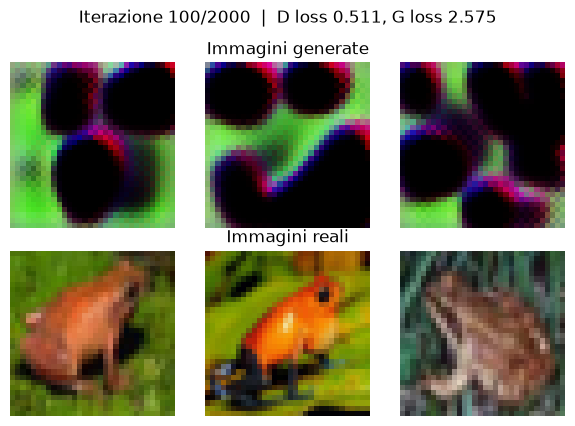

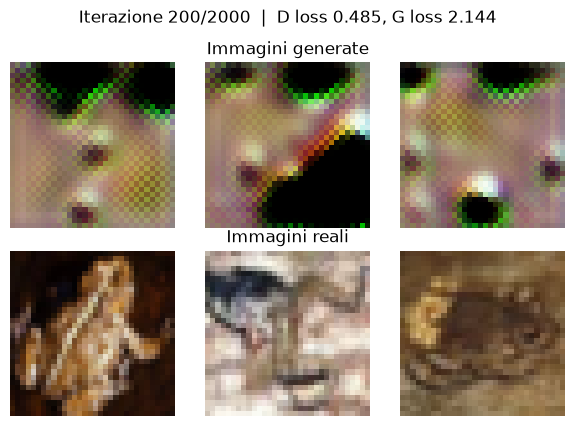

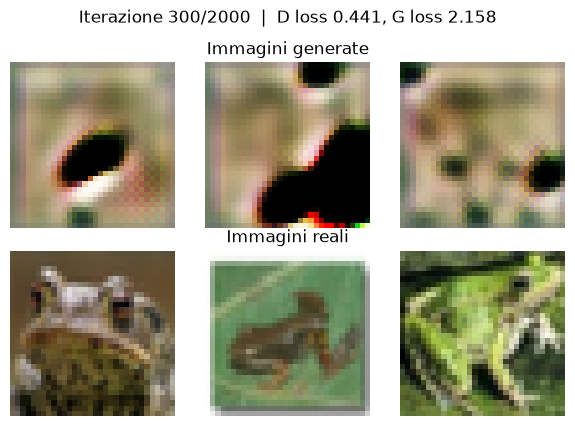

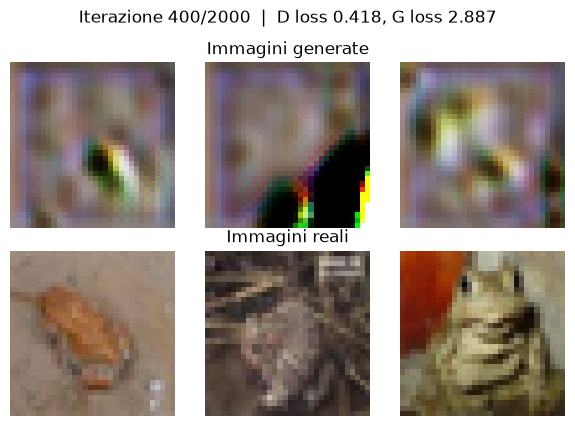

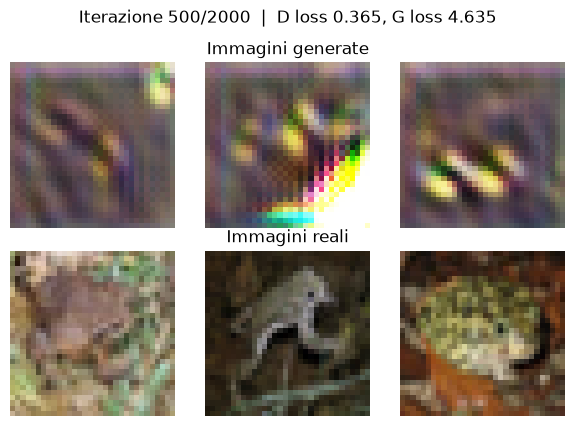

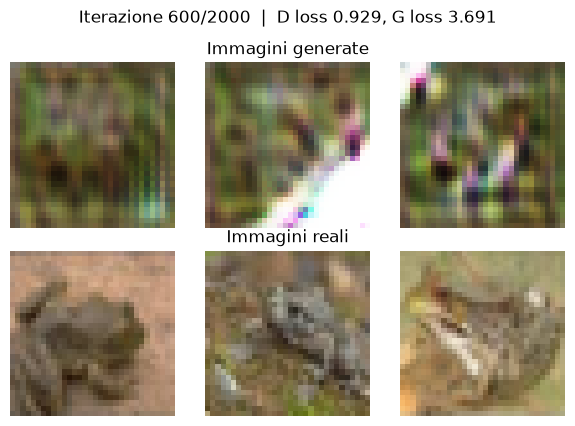

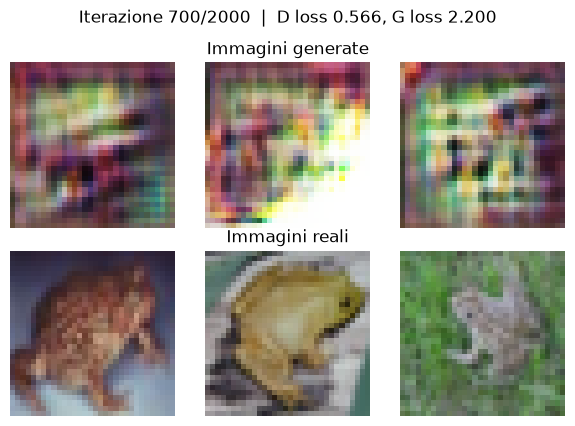

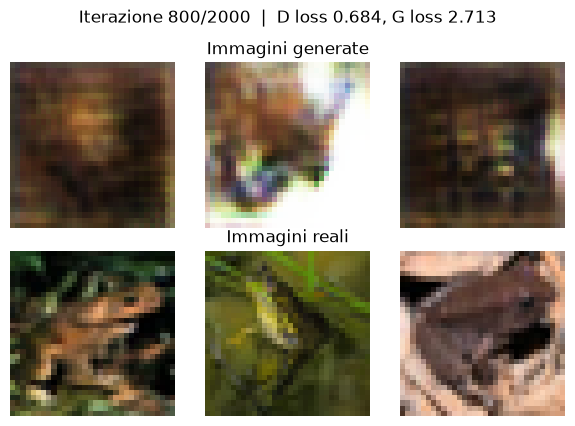

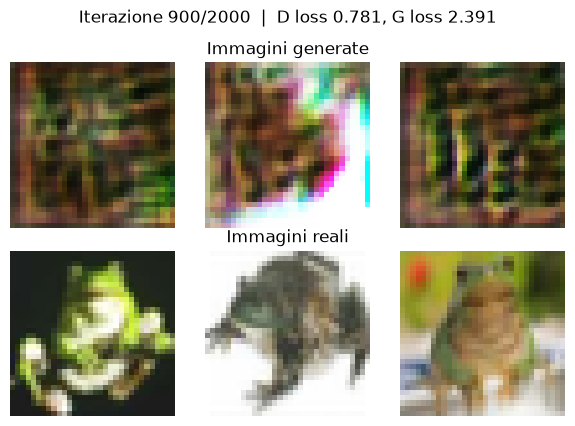

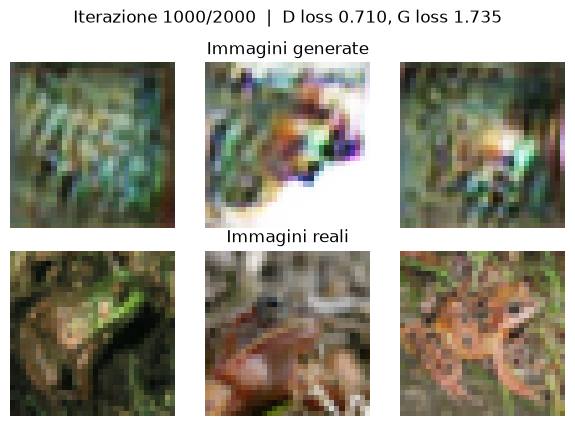

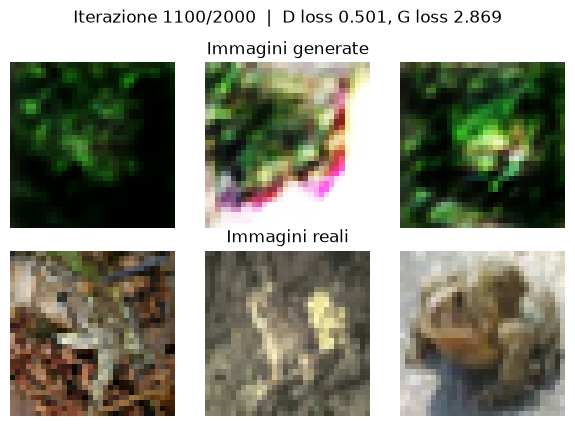

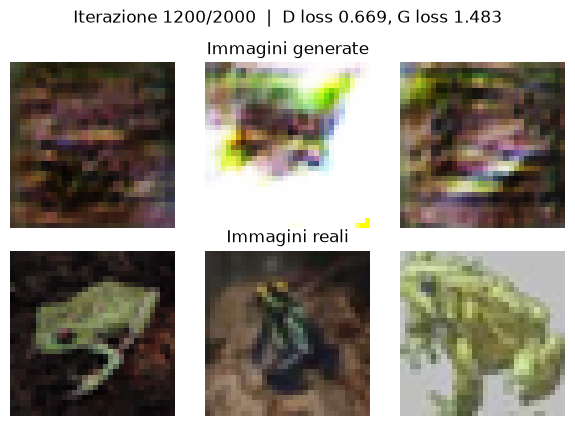

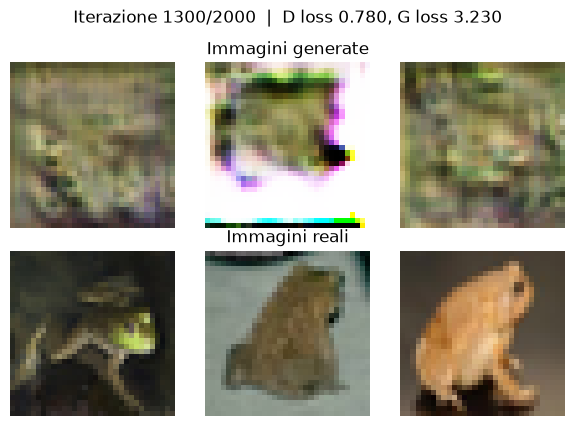

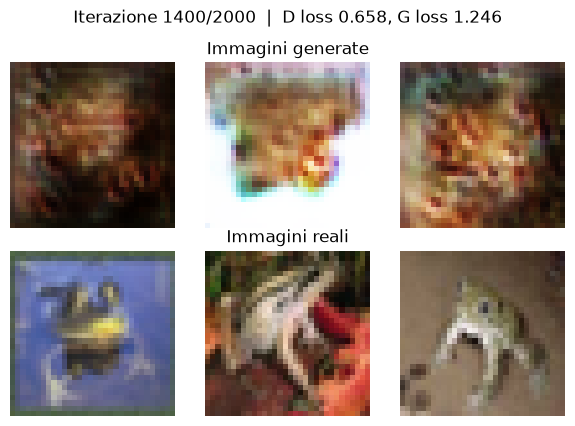

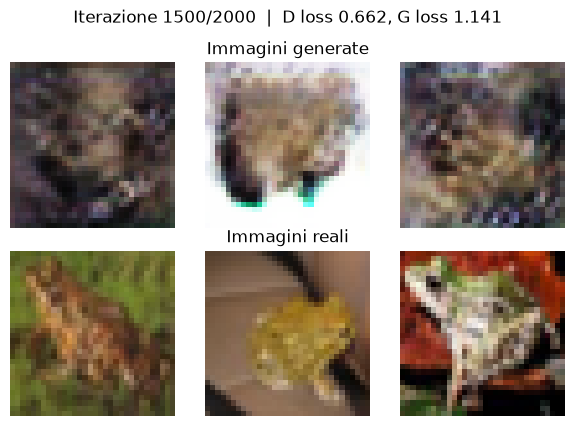

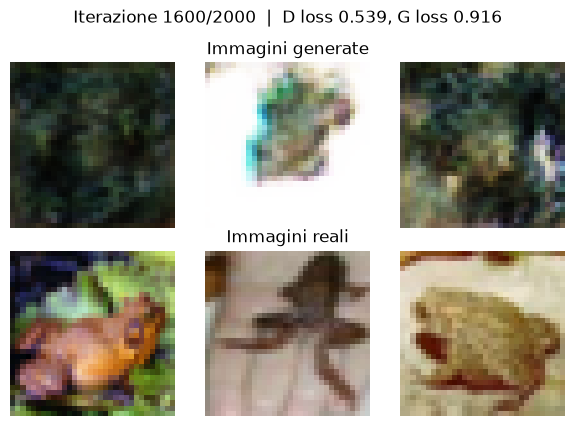

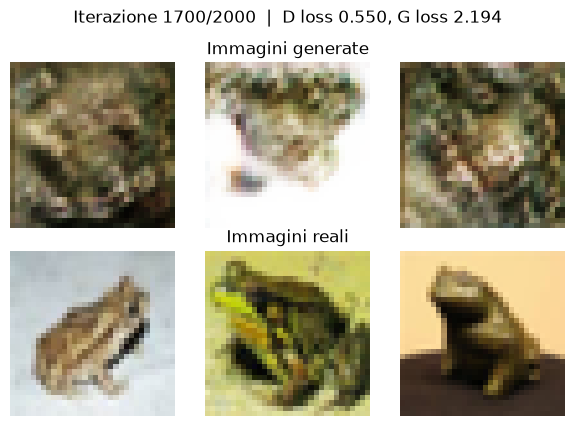

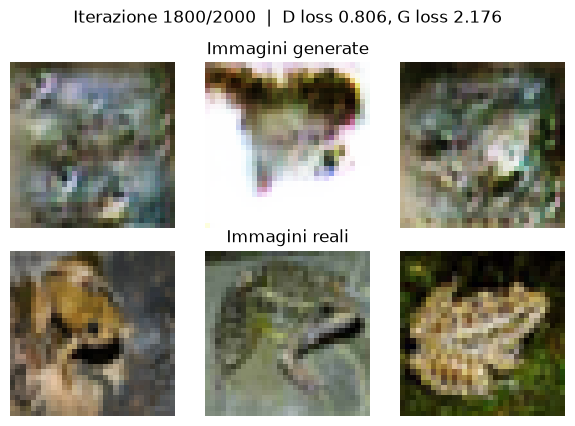

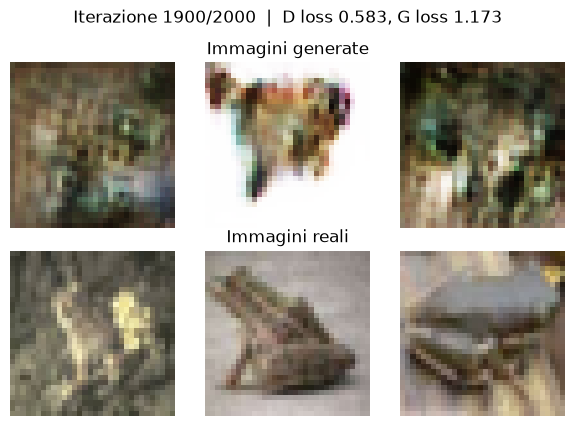

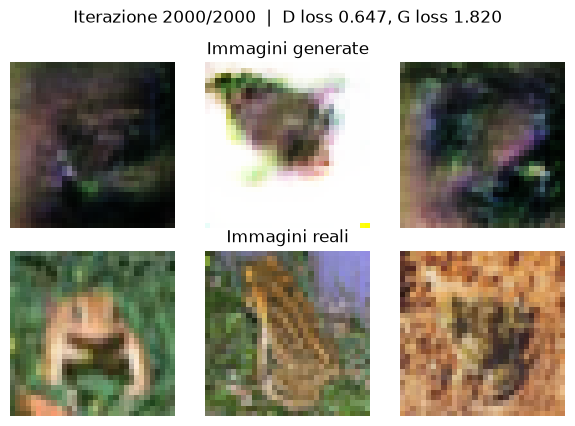

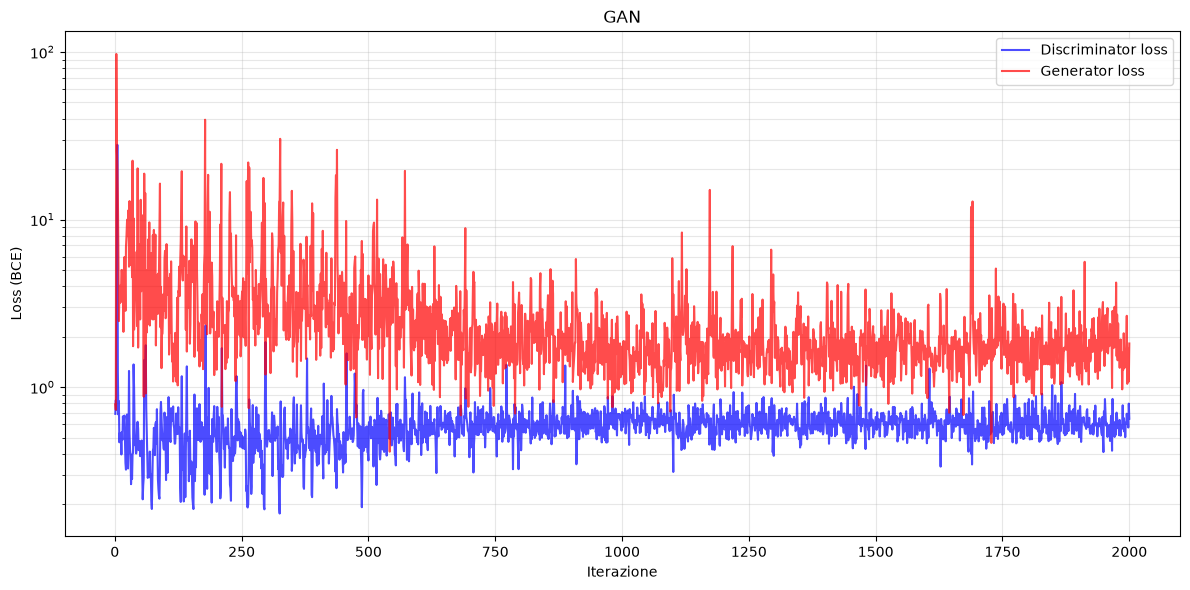

In [8]:
os.makedirs('histories', exist_ok=True)

filename = "prova"
hist_path = f'histories/{filename}.hist'
g_weights_path = f'histories/{filename}_generator.pt'
d_weights_path = f'histories/{filename}_discriminator.pt'

if os.path.isfile(hist_path) and os.path.isfile(g_weights_path) and os.path.isfile(d_weights_path):
    with open(hist_path, 'rb') as hist_file:
        history_dict = pickle.load(hist_file)
    generator.load_state_dict(torch.load(g_weights_path, map_location=DEVICE))
    discriminator.load_state_dict(torch.load(d_weights_path, map_location=DEVICE))
else:
    history_dict = utils.train_gan(generator, discriminator, g_optimizer, d_optimizer, criterion,
                                   train_loader, LATENT_SIZE, DEVICE, DISPLAY_INTERVAL)
    with open(hist_path, 'wb') as hist_file:
        pickle.dump(history_dict, hist_file)
    torch.save(generator.state_dict(), g_weights_path)
    torch.save(discriminator.state_dict(), d_weights_path)

iterations = range(1, len(history_dict['d_loss']) + 1)
plt.figure(figsize=(12, 6))
plt.plot(iterations, history_dict['d_loss'], 'b-', label='Discriminator loss', linewidth=1.5, alpha=0.7)
plt.plot(iterations, history_dict['g_loss'], 'r-', label='Generator loss', linewidth=1.5, alpha=0.7)
plt.title('GAN')
plt.xlabel('Iterazione')
plt.ylabel('Loss (BCE)')
plt.yscale('log')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()

# VALUTAZIONE

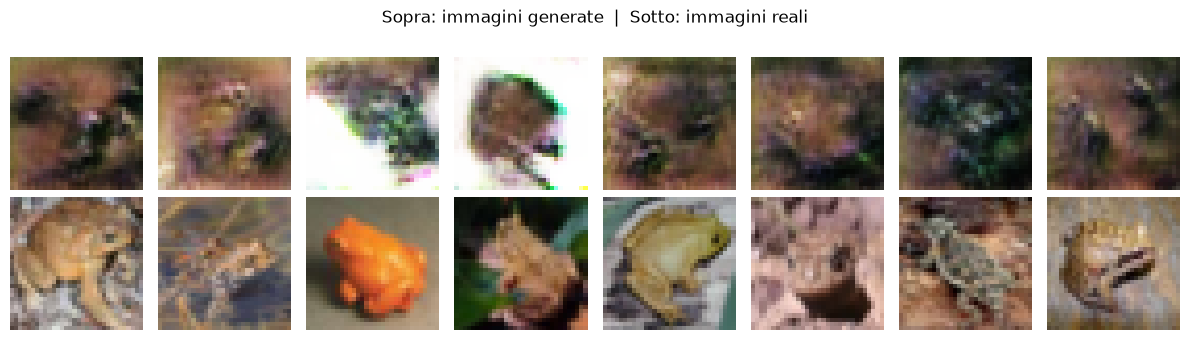

In [9]:
# TEST: immagini generate da rumore casuale a confronto con immagini reali
n_show = 8
generator.eval()
with torch.no_grad():
    z = torch.randn(n_show, LATENT_SIZE, device=DEVICE)
    generated = generator(z).cpu()
real = x_train[torch.randint(len(x_train), (n_show,))]

plt.figure(figsize=(1.5 * n_show, 3.5))
for i in range(n_show):
    plt.subplot(2, n_show, i + 1)
    plt.imshow(((generated[i] + 1) / 2).clamp(0, 1).permute(1, 2, 0))
    plt.axis('off')
    plt.subplot(2, n_show, n_show + i + 1)
    plt.imshow(((real[i] + 1) / 2).permute(1, 2, 0))
    plt.axis('off')
plt.suptitle('Sopra: immagini generate  |  Sotto: immagini reali')
plt.tight_layout()
plt.show()